# Heart Disease Modelling Project

#### Loading Dataset

In [459]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 

In [460]:
# Importing necessaries libraries to use later on
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# Ignoring the unnecessary 'red' warnings in the notebook
import warnings
warnings.filterwarnings("ignore")

## 3.1 EDA and Data-Preprocessing

In [461]:
# Extracting the core values from the data
X.describe()

# feature 'cal' has 4 NaN values and feature 'thal' has 2 NaN

ca_median = X.describe()['ca'].iloc[5]         # Indexing the '50%' value or median using its row index 5
thal_median = X.describe()['thal'].iloc[5]

# Replace them with the median of the respective features
X.loc[(X['ca'].isnull() == True), ['ca']] = ca_median
X.loc[(X['thal'].isnull() == True), ['thal']] = thal_median

# Labelling the target data 
y.loc[(y['num'] == 0), ['num']] = 0
y.loc[(y['num'] > 0) & (y['num'] < 5) , ['num']] = 1

# Reshaping 'y' to a standard horizontal matrix (1xn instead of nx1)
y_array = np.array(y).reshape(y.count())

# Summarizing the X dataframe after filling the null values with respective column medians
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,4.722772
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,1.938383
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


In [462]:
# Normalizing the data using StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_X = scaler.fit_transform(X)

## 3.2 Heart Disease Prediction

#### Logistic Regression Model

In [463]:
# Splitting the data into train and test data for LR Model
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(scaled_X, y_array, test_size=0.2, random_state=0)

from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

#### Evaluation of Logistic Regression Model

In [464]:
# Importing the evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, precision_score

# Evaluation of the LR model on test data
print("\033[1m" + 'Evaluation of the Logistic Regression Model' + "\033[0m\n")

# Classification Report of the LR Model
from sklearn.metrics import classification_report

print(f'Classification Report (LR):\n {classification_report(y_test, y_pred_lr)}')

# Accuracy 
print(f'Accuracy (LR):', accuracy_score(y_test, y_pred_lr), '\n')

# Precision
print(f'Precision (LR):', precision_score(y_test, y_pred_lr), '\n')

# Recall 
print(f'Recall (LR):', recall_score(y_test, y_pred_lr), '\n')

# F1-Score
print(f'F1-Score (LR):', f1_score(y_test, y_pred_lr), '\n')

# Confusion Matrix
print(f'Confusion Matrix (LR):\n', confusion_matrix(y_test, y_pred_lr), '\n')

Evaluation of the Logistic Regression Model

Classification Report (LR):
               precision    recall  f1-score   support

           0       0.78      0.89      0.83        35
           1       0.81      0.65      0.72        26

    accuracy                           0.79        61
   macro avg       0.79      0.77      0.78        61
weighted avg       0.79      0.79      0.78        61

Accuracy (LR): 0.7868852459016393 

Precision (LR): 0.8095238095238095 

Recall (LR): 0.6538461538461539 

F1-Score (LR): 0.723404255319149 

Confusion Matrix (LR):
 [[31  4]
 [ 9 17]] 



#### Random Forest Classifier Model

In [465]:
# Splitting the data into train and test data for RFC Model
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(scaled_X, y_array, test_size=0.2, random_state=0)

# Setting up the Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rfc_model = RandomForestClassifier(random_state=0, criterion='gini')
rfc_model.fit(X_train, y_train)

y_pred_rfc = rfc_model.predict(X_test)

#### Evaluation of Random Forest Classifier Model

In [466]:
# Importing the evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, precision_score

# Evaluating the RFC Model
print("\033[1m" + 'Evaluation of the Random Forest Classifier Model' + "\033[0m\n")

# Classification Report of the RFC Model
from sklearn.metrics import classification_report

print(f'Classification Report (RFC):\n {classification_report(y_test, y_pred_rfc)}')

# Accuracy 
print(f'Accuracy (RFC):', accuracy_score(y_test, y_pred_rfc), '\n')

# Precision
print(f'Precision (RFC):', precision_score(y_test, y_pred_rfc), '\n')

# Recall 
print(f'Recall (RFC):', recall_score(y_test, y_pred_rfc), '\n')

# F1-Score
print(f'F1-Score (RFC):', f1_score(y_test, y_pred_rfc), '\n')

# Confusion Matrix
print(f'Confusion Matrix (RFC):\n', confusion_matrix(y_test, y_pred_rfc), '\n')

Evaluation of the Random Forest Classifier Model

Classification Report (RFC):
               precision    recall  f1-score   support

           0       0.74      0.83      0.78        35
           1       0.73      0.62      0.67        26

    accuracy                           0.74        61
   macro avg       0.74      0.72      0.73        61
weighted avg       0.74      0.74      0.73        61

Accuracy (RFC): 0.7377049180327869 

Precision (RFC): 0.7272727272727273 

Recall (RFC): 0.6153846153846154 

F1-Score (RFC): 0.6666666666666666 

Confusion Matrix (RFC):
 [[29  6]
 [10 16]] 



### Comparing the Logistic Regression and Random Forest Classifier Model's

<font size='3'>
<br>To compare the two machine learning models we need to understand what are we actually predicting. We are trying to predict on the basis of different biological and physical features whether a person has a heart disease or not. So our model needs to be very careful in its predictions. We need to minimize the False Negative (FP) errors on priority i.e. to minimize the cases where we predict that a person does not have a heart disease but actually he has. Such Predictions can have fatal consequences. Minimizing the False Negatives (FP) means that we need to choose a model that has high 'Recall Score' and 'Accuracy' and if 'Recall Score' increases generally the 'Precision' decreases.</br>

<br>So among the two models, the 'Logisitic Regression' Model has a higher average and class 'Recall Score' as well as 'Accuracy' than the 'Random Forest Classifier' Model. So in predicting whether a person has a heart condition or not, our 'Logisitic Regression' Model will be useful than the other one because of it's high 'Recall Score'.</br>

## 3.3 Cholesterol Level Prediction

#### Multiple Linear Regression Model for Cholesterol Level Predicition

In [467]:
# Feature Data without the 'Cholesterol' Column 
X_chol = X.drop(columns = ['chol'])
X_chol
y_chol = X['chol']
y_chol_array = np.array(y_chol).reshape(y_chol.count())

# Normalizing the the Feature columns
chol_scaler = StandardScaler()
scaled_X_chol = chol_scaler.fit_transform(X_chol)
pd.DataFrame(scaled_X_chol)

# Splitting the data in train and test data for Multiple Linear Regression Model
X_train, X_test, y_train, y_test = train_test_split(scaled_X_chol, y_chol_array, test_size=0.2, random_state=0)

# Multiple Linear Regression Model
from sklearn.linear_model import LinearRegression

mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 6.75,-7.51, 0.97,...,-3.75, 3.94,-0.61]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,245.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,12
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[27.49,19.18,17.15,...,10.5 ,10.04, 9.54]"


#### Visualizing the Multiple Linear Regression Model for Cholesterol Level Prediction

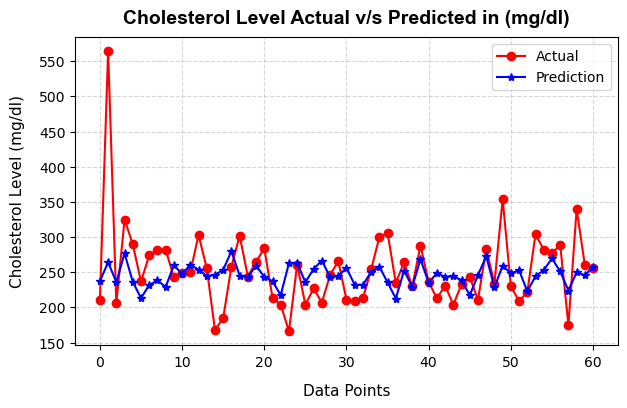

In [468]:
# Prediction
y_pred_mlr = mlr_model.predict(X_test)

# Visualizing the MLR Results
plt.figure(figsize=(7,4))
data_points = np.arange(len(y_test))
plt.plot(data_points, y_test, color = 'r', label='Actual' , marker = 'o')
plt.plot(data_points, y_pred_mlr, color='blue', label='Prediction', marker='*')
plt.xlabel('Data Points', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.ylabel('Cholesterol Level (mg/dl)', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.title('Cholesterol Level Actual v/s Predicted in (mg/dl)', fontdict={'weight': 'bold', 'fontsize': 14, 'family': 'Arial'} , pad = 10.0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

#### Analyzing the Cholesterol Level Data (Using Correlation Matrix and Heat Map)

In [469]:
# Correlation Matrix
correlation_matrix = X.corr()
correlation_matrix

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
age,1.000000,-0.097542,0.104139,0.284946,0.208950,0.118530,0.148868,-0.393806,0.091661,0.203805,0.161770,0.365323,0.128303
sex,-0.097542,1.000000,0.010084,-0.064456,-0.199915,0.047862,0.021647,-0.048663,0.146201,0.102173,0.037533,0.086048,0.380581
cp,0.104139,0.010084,1.000000,-0.036077,0.072319,-0.039975,0.067505,-0.334422,0.384060,0.202277,0.152050,0.233117,0.262089
trestbps,0.284946,-0.064456,-0.036077,1.000000,0.130120,0.175340,0.146560,-0.045351,0.064762,0.189171,0.117382,0.097528,0.134424
chol,0.208950,-0.199915,0.072319,0.130120,1.000000,0.009841,0.171043,-0.003432,0.061310,0.046564,-0.004062,0.123726,0.018351
fbs,0.118530,0.047862,-0.039975,0.175340,0.009841,1.000000,0.069564,-0.007854,0.025665,0.005747,0.059894,0.140764,0.064625
restecg,0.148868,0.021647,0.067505,0.146560,0.171043,0.069564,1.000000,-0.083389,0.084867,0.114133,0.133946,0.131749,0.024325
thalach,-0.393806,-0.048663,-0.334422,-0.045351,-0.003432,-0.007854,-0.083389,1.000000,-0.378103,-0.343085,-0.385601,-0.265699,-0.274142
exang,0.091661,0.146201,0.384060,0.064762,0.061310,0.025665,0.084867,-0.378103,1.000000,0.288223,0.257748,0.145788,0.325240
oldpeak,0.203805,0.102173,0.202277,0.189171,0.046564,0.005747,0.114133,-0.343085,0.288223,1.000000,0.577537,0.301067,0.342405



Here , the Darker colors represent higher values and Lighter colors represent lower values
Range of values is from 0 to 1 i.e. the range of coefficient of correlation is from 0 to 1

The feature 'Age' is most correlated with serum cholesterol as it has a much darker color in the heat map and higher value in the correlation matrix
NOTE: Feature 'Age' has the highest value (after comparing 'Age' and 'restecg' to further decimal places)



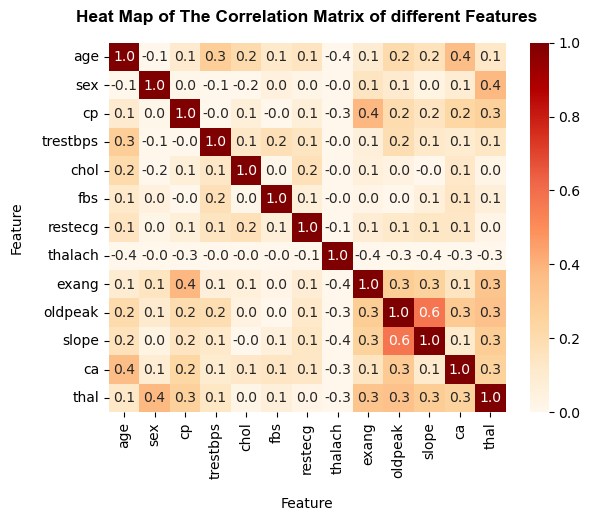

In [470]:
# Heat-Map to visualize the correlation matrix
import seaborn as sns
heatmap = sns.heatmap(correlation_matrix, vmin=0 , vmax =  1, cmap='OrRd', annot=True , fmt='.1f')      # fmt = '.1f' rounds to one decimal place
heatmap.set_title(label='Heat Map of The Correlation Matrix of different Features', fontdict={'weight':'bold', 'family':'Arial', 'fontsize': 12.5}, pad=15)
heatmap.set_xlabel(xlabel='Feature', labelpad=13.0, fontdict={ 'family':'Sans-Serif', 'fontsize':10})
heatmap.set_ylabel(ylabel='Feature', labelpad=13.0, fontdict={ 'family':'Sans-Serif', 'fontsize':10})
print("\033[1m" + '\nHere , the Darker colors represent higher values and Lighter colors represent lower values' + "\033[0m") 
print("\033[1m" + 'Range of values is from 0 to 1 i.e. the range of coefficient of correlation is from 0 to 1\n' + "\033[0m")
print("\033[1m" + 'The feature \'Age\' is most correlated with serum cholesterol as it has a much darker color in the heat map and higher value in the correlation matrix' + "\033[0m")
print("\033[1m" + 'NOTE: Feature \'Age\' has the highest value (after comparing \'Age\' and \'restecg\' to further decimal places)\n' + "\033[0m")


## 3.4 Principal Component Analysis


Variance Retained: 97.278203
Dimensions Retained: 12
Shape of Reduced Data: 303 rows x 12 columns



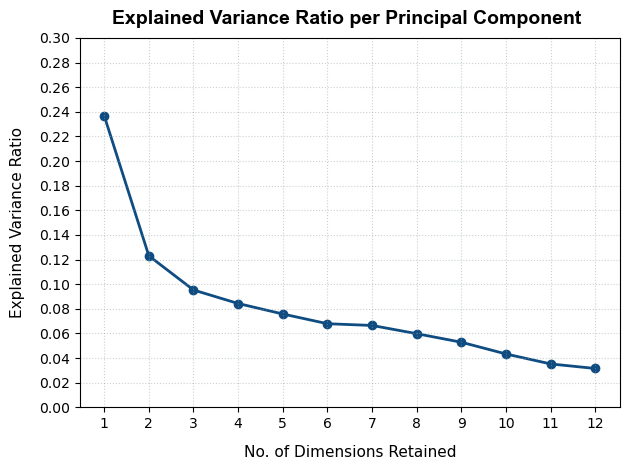

In [471]:
# Normalizing the data for principal component analysis
normalized_X = StandardScaler().fit_transform(X)

# Implementing PCA 
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95, random_state=0)
X_nd = pca.fit_transform(normalized_X)

explained_variance_ratio_array = pca.explained_variance_ratio_
explained_variance_array = pca.explained_variance_
variance_retained = (explained_variance_ratio_array.sum()) * 100 
dimensions_retained = pca.n_components_

# Printing some Results
print("\033[1m" + f'\nVariance Retained: {np.round(variance_retained,6)}' + "\033[0m")
print("\033[1m" + f'Dimensions Retained: {dimensions_retained}' + "\033[0m")
print("\033[1m" + f'Shape of Reduced Data: {pca.n_samples_} rows x {pca.n_components_} columns\n' + "\033[0m")

# Plot depicting the explained variance ratio (out of 1) by each dimension or feature
feature_indices = np.arange(1,(pca.n_components_)+1)
yticks_arr = np.linspace(0.00,0.30, num = 16)
plt.plot(feature_indices, explained_variance_ratio_array, color='#0F4C81', linestyle='-', linewidth=2, zorder=1 , marker='o')

# Titling and Labeling
plt.title('Explained Variance Ratio per Principal Component ', fontdict={'weight': 'bold', 'fontsize': 14, 'family': 'Arial'} , pad = 10.0)
plt.xlabel('No. of Dimensions Retained', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.ylabel('Explained Variance Ratio' , fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.xticks(ticks=feature_indices)
plt.yticks(ticks=yticks_arr)

# Grid and Displaying the Plot
plt.grid(True, linestyle=':', alpha=0.5, color='#95a5a6')
plt.tight_layout()
plt.show()

## 3.5 Grouping Patients based on Health Profiles (K-Means Clustering)

#### Elbow Graph for Optimal Value of K

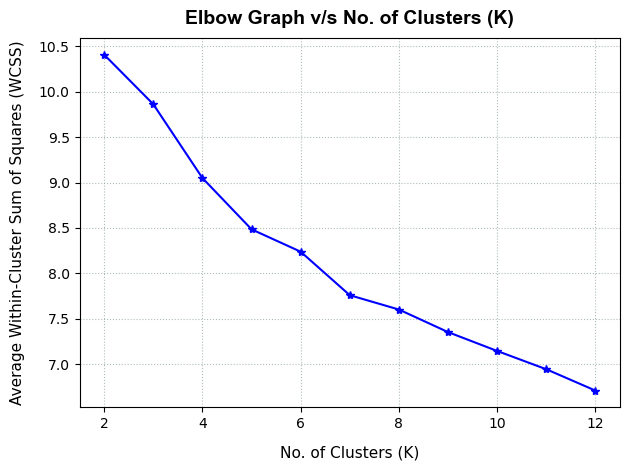

In [472]:
# Applying K-Means clustering on the PCA reduced dataset
from sklearn.cluster import KMeans

# Applying Elbow Method for various values of K

# List for storing the values for wcds (within cluster distance squared) values for k = 2 to k = 12
wcds_list = []

# Looping and calculating wcds_k for k = 2 to k = 12
for k in range(2,13) :
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans_labels = kmeans.fit_predict(X_nd)

    # Cluster-Center Distance Array (for each row/example shows the distances of that row/example from the particular cluster centers)
    X_k = kmeans.fit_transform(X_nd)
    wcds_k = 0

    for row in X_k:
        wcds_k += float((row.min()**2))

    # Storing all the wcds values
    wcds_list.append(wcds_k)

k_values = [k for k in range(2,13)]
average_wcds_list = np.array(wcds_list)/303
plt.plot(k_values, average_wcds_list, color='blue', marker='*')

# Titling and Labeling
plt.title('Elbow Graph v/s No. of Clusters (K)', fontdict={'weight': 'bold', 'fontsize': 14, 'family': 'Arial'} , pad = 10.0)
plt.xlabel('No. of Clusters (K)', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.ylabel('Average Within-Cluster Sum of Squares (WCSS)', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)

# Grid and Displaying the Plot
plt.grid(True, linestyle=':', alpha=0.75, color='#95a5a6')
plt.tight_layout()
plt.show()

#### Silhouette Score Graph for Optimal Value of K

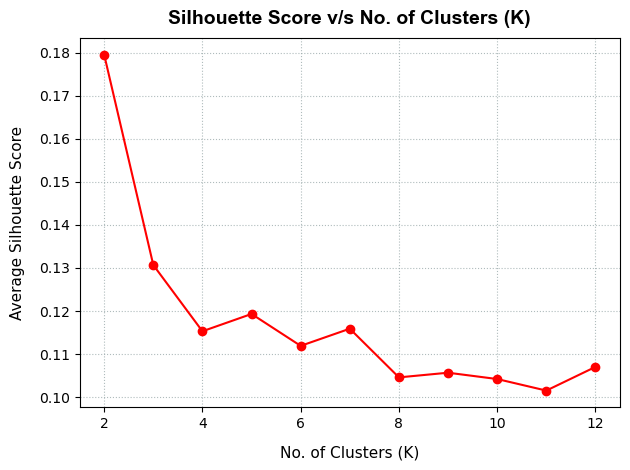

In [473]:
# Silhouette Method For Optimal Value of K      # Takes two params (Feature data to cluster) and (labels of the clusters after clustering)
from sklearn.metrics import silhouette_score

silhouette_score_list = []
for k in range(2,13):
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans_labels = kmeans.fit_predict(X_nd)
    silhouette_score_list.append(silhouette_score(X_nd, kmeans_labels))

k_values = [k for k in range(2,13)]
plt.plot(k_values, silhouette_score_list, color='red', marker='o')
plt.title('Silhouette Score v/s No. of Clusters (K)', fontdict={'weight': 'bold', 'fontsize': 14, 'family': 'Arial'} , pad = 10.0)
plt.xlabel('No. of Clusters (K)', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.ylabel('Average Silhouette Score', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.grid(True, linestyle=':', alpha=0.75, color='#95a5a6')
plt.tight_layout()
plt.show()

#### Optimal No. of Clusters (Optimal Value of K)

<font size="3"><b>To find the best number of clusters, I looked at both the Elbow and Silhouette plots together. Because keeping 95% variance left us with 12 dimensions, the graphs doesn't look perfectly like a textbook-one, which is normal as our data is spread out across so many features. However, K = 5 stands out as the best choice. The Silhouette graph shows a clear local peak at 5, meaning the groups are tightly formed there, and the Elbow graph shows a slight bend right at that same spot.</b></font>

#### Visualizing the Clusters  (K = 5)

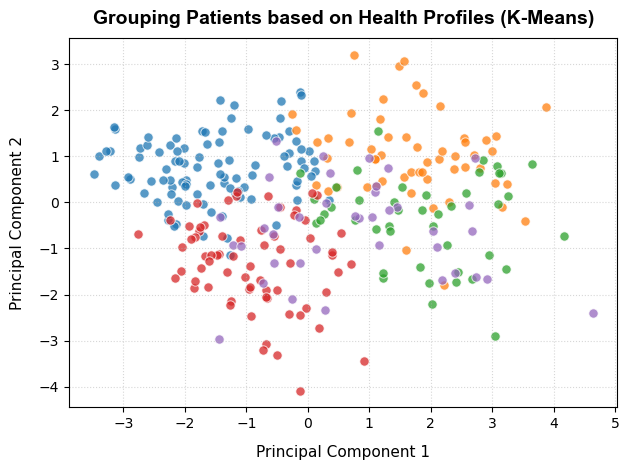

In [474]:
# Visualizing the cluster plot
kmeans = KMeans(n_clusters=5, random_state=0)
kmeans_labels = kmeans.fit_predict(X_nd)

X_k5_c1 = X_nd[kmeans_labels == 0]
X_k5_c2 = X_nd[kmeans_labels == 1]
X_k5_c3 = X_nd[kmeans_labels == 2]
X_k5_c4 = X_nd[kmeans_labels == 3]
X_k5_c5 = X_nd[kmeans_labels == 4]

# Title , X, Y Labels
plt.title('Grouping Patients based on Health Profiles (K-Means)', fontdict={'weight': 'bold', 'fontsize': 14, 'family': 'Arial'} , pad = 10.0)
plt.xlabel('Principal Component 1', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)
plt.ylabel('Principal Component 2', fontdict = {'fontsize': 11, 'family': 'Sans-Serif'}, labelpad = 10.0)

# Colors for visual appeal
colors = ['#1f77b4', '#4682b4', '#d95f02', '#1b9e77', '#34495e']
color_map = [colors[label] for label in kmeans_labels]

# Plotting
plt.scatter(X_k5_c1[:,0], X_k5_c1[:,1], cmap=color_map, alpha=0.75, edgecolors='white', linewidths=0.7, s=45)
plt.scatter(X_k5_c2[:,0], X_k5_c2[:,1], cmap=color_map, alpha=0.75, edgecolors='white', linewidths=0.7, s=45)
plt.scatter(X_k5_c3[:,0], X_k5_c3[:,1], cmap=color_map, alpha=0.75, edgecolors='white', linewidths=0.7, s=45)
plt.scatter(X_k5_c4[:,0], X_k5_c4[:,1], cmap=color_map, alpha=0.75, edgecolors='white', linewidths=0.7, s=45)
plt.scatter(X_k5_c5[:,0], X_k5_c5[:,1], cmap=color_map, alpha=0.75, edgecolors='white', linewidths=0.7, s=45)

# Grid and Final Display
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()